# Clasificación de compuertas lógicas dibujadas a mano

**PC2 · Computación Gráfica · UNI**

**Problema:** digitalizar circuitos lógicos dibujados a mano. Como primer paso, una red neuronal debe reconocer qué compuerta se dibujó.

**Clases (7):** AND, OR, NOT, NAND, NOR, XOR y **OTRO** (cualquier dibujo que no es una de esas 6 compuertas: letras, números, formas, flechas, garabatos). Sin esta clase, la red tiene que elegir una compuerta aunque le muestren un círculo o una letra.

**Datos:** dibujos recolectados por el equipo con la app web del repositorio (lienzo de 256×256). Cada PNG está en una carpeta con el nombre de su clase y el trazo va en el canal alfa. Los 500 dibujos de OTRO se generaron por programa (`generar_otro.py`) imitando el trazo del lienzo; su autor figura como `sintetico`.

**Contenido del notebook**
1. Carga de datos
2. Preprocesamiento
3. Exploración del dataset
4. División en entrenamiento, validación y prueba
5. Modelo base: perceptrón multicapa (MLP)
6. Red neuronal convolucional (CNN)
7. Métricas: accuracy, precisión, recall, F1 y matriz de confusión
8. Análisis de errores y parejas difíciles (AND/NAND, OR/NOR, OR/XOR)
9. Experimento: ¿cuánto importa la resolución de la imagen?
10. Generalización a personas que no participaron en el entrenamiento
11. Global Average Pooling y Class Activation Maps (CAM)
12. Conclusiones

## 1. Carga de datos

El dataset final está en el repositorio como `dataset.zip`: 3500 dibujos, 500 por clase: 3000 compuertas dibujadas por el equipo en la app desplegada y 500 de OTRO generados con `generar_otro.py`. Si el archivo no está en la carpeta actual (por ejemplo, al abrir el notebook en Colab), se descarga del repositorio.

In [1]:
import os, io, json, zipfile, urllib.request, collections
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

URL_DATASET = "https://github.com/Faalvial/compuertas_logicas/raw/main/dataset.zip"
RUTA_ZIP = "dataset.zip"
CARPETA = "dataset"
CLASES = ["AND", "OR", "NOT", "NAND", "NOR", "XOR", "OTRO"]

if not os.path.exists(RUTA_ZIP):
    print("Descargando", URL_DATASET)
    urllib.request.urlretrieve(URL_DATASET, RUTA_ZIP)

with zipfile.ZipFile(RUTA_ZIP) as zf:
    zf.extractall(CARPETA)
print("Dataset extraído en", CARPETA)

Dataset extraído en dataset


## 2. Preprocesamiento

Cada dibujo pasa por estos pasos:
1. **Canal alfa:** el lienzo es transparente y el trazo es opaco, así que el canal alfa ya es la imagen en escala de grises (0 = fondo, 255 = tinta).
2. **Recorte:** se recorta al rectángulo que contiene la tinta, con un margen. Así no importa en qué parte del lienzo ni de qué tamaño dibujó cada persona.
3. **Cuadrado:** se rellena con fondo para que quede cuadrado sin deformar la compuerta.
4. **Redimensionar:** a `TAM × TAM` píxeles (64 por defecto) y normalizar a valores entre 0 y 1.

Los recortes cuadrados se guardan a resolución completa para poder generar luego versiones de 16, 28 o 64 píxeles en el experimento de resolución.

In [2]:
TAM = 64
MARGEN = 0.08

def recortar_cuadrado(ruta, margen=MARGEN):
    alfa = Image.open(ruta).convert("RGBA").getchannel("A")
    caja = alfa.getbbox()                     # rectángulo con tinta
    if caja is None:
        return None
    x0, y0, x1, y1 = caja
    lado = int(max(x1 - x0, y1 - y0) * (1 + 2 * margen))
    cuadrado = Image.new("L", (lado, lado), 0)
    cuadrado.paste(alfa.crop(caja), ((lado - (x1 - x0)) // 2, (lado - (y1 - y0)) // 2))
    return cuadrado

def a_matriz(recortes, tam):
    return np.stack([np.asarray(r.resize((tam, tam), Image.Resampling.LANCZOS), dtype=np.float32) / 255.0
                     for r in recortes])

recortes, etiquetas, autores, archivos = [], [], [], []
for i, clase in enumerate(CLASES):
    carpeta = os.path.join(CARPETA, clase)
    for nombre in sorted(os.listdir(carpeta)):
        if not nombre.endswith(".png"):
            continue
        r = recortar_cuadrado(os.path.join(carpeta, nombre))
        if r is None:
            continue
        recortes.append(r)
        etiquetas.append(i)
        partes = nombre.split("_")
        autores.append(partes[1] if len(partes) >= 3 else "anonimo")
        archivos.append(f"{clase}/{nombre}")

y = np.array(etiquetas)
autores = np.array(autores)
X = a_matriz(recortes, TAM)
print("Imágenes:", X.shape, " Etiquetas:", y.shape)

Imágenes: (3500, 64, 64)  Etiquetas: (3500,)


## 3. Exploración del dataset

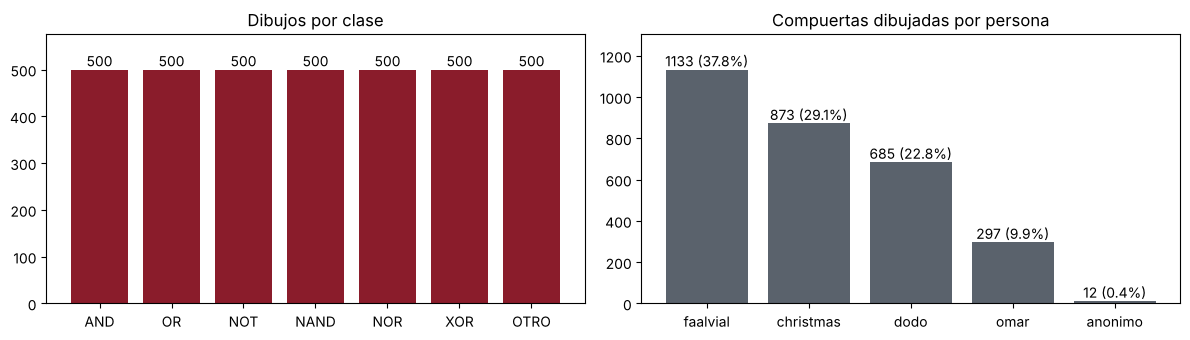

{'AND': 500, 'OR': 500, 'NOT': 500, 'NAND': 500, 'NOR': 500, 'XOR': 500, 'OTRO': 500}  total: 3500


In [3]:
conteo = np.bincount(y, minlength=len(CLASES))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(CLASES, conteo, color="#8a1c2b")
ax[0].set_title("Dibujos por clase")
for i, n in enumerate(conteo):
    ax[0].text(i, n, str(n), ha="center", va="bottom")
ax[0].set_ylim(0, conteo.max() * 1.15)
por_autor = collections.Counter(a for a in autores if a != "sintetico")  # solo dibujos del equipo
nombres = [a for a, _ in por_autor.most_common()]
ax[1].bar(nombres, [por_autor[a] for a in nombres], color="#5a626c")
ax[1].set_title("Compuertas dibujadas por persona")
for i, a in enumerate(nombres):
    ax[1].text(i, por_autor[a], f"{por_autor[a]} ({por_autor[a] / sum(por_autor.values()):.1%})", ha="center", va="bottom")
ax[1].set_ylim(0, max(por_autor.values()) * 1.15)
plt.tight_layout(); plt.show()
print(dict(zip(CLASES, conteo.tolist())), " total:", conteo.sum())

**Aporte de cada persona** a las 6 compuertas. `anonimo` son los dibujos enviados sin nombre. Los dibujos de OTRO son generados y no cuentan aquí.

In [4]:
COMPUERTAS_6 = [c for c in CLASES if c != "OTRO"]
del_equipo = autores != "sintetico"
print(f"{'Persona':<12}" + "".join(f"{c:>6}" for c in COMPUERTAS_6) + f"{'Total':>7}{'Aporte':>8}")
for a in nombres:
    fila = [int(((autores == a) & (y == CLASES.index(c))).sum()) for c in COMPUERTAS_6]
    print(f"{a:<12}" + "".join(f"{n:>6}" for n in fila) + f"{sum(fila):>7}{sum(fila) / del_equipo.sum():>8.1%}")
totales = [int(((y == CLASES.index(c)) & del_equipo).sum()) for c in COMPUERTAS_6]
print(f"{'Total':<12}" + "".join(f"{n:>6}" for n in totales) + f"{sum(totales):>7}{1:>8.0%}")

Persona        AND    OR   NOT  NAND   NOR   XOR  Total  Aporte
faalvial       185   188   188   190   190   192   1133   37.8%
christmas      149   144   142   147   152   139    873   29.1%
dodo           116   120   116   110   108   115    685   22.8%
omar            50    46    51    50    48    52    297    9.9%
anonimo          0     2     3     3     2     2     12    0.4%
Total          500   500   500   500   500   500   3000    100%


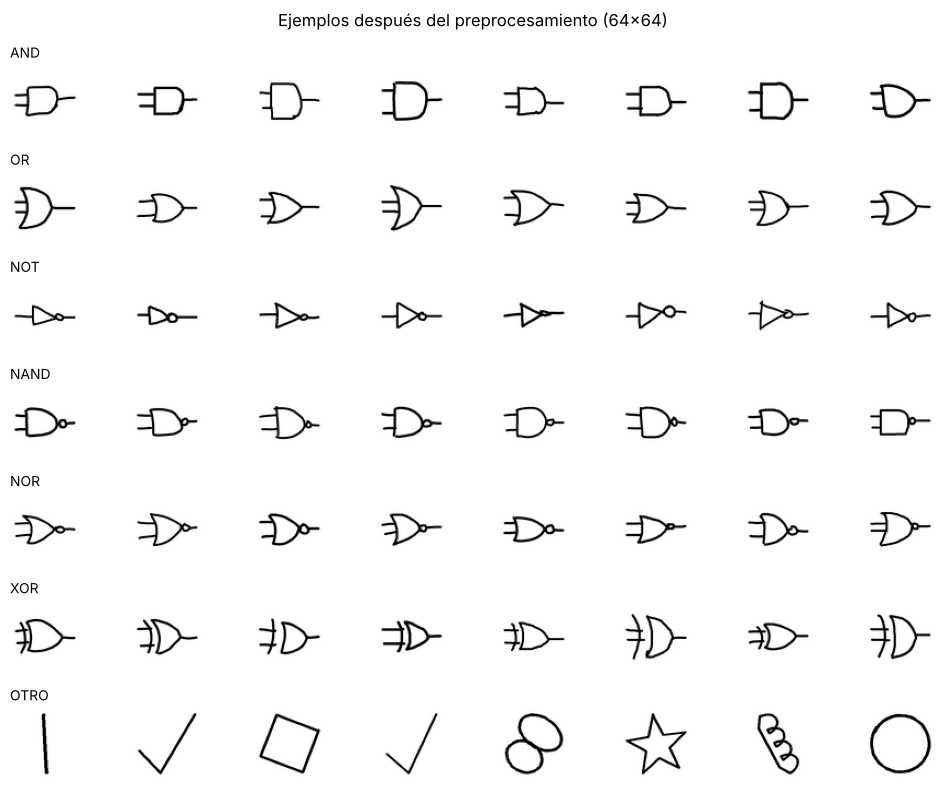

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASES), 8, figsize=(10, 8))
for i, clase in enumerate(CLASES):
    idx = rng.choice(np.where(y == i)[0], size=min(8, (y == i).sum()), replace=False)
    for j in range(8):
        a = axes[i, j]; a.axis("off")
        if j < len(idx):
            a.imshow(X[idx[j]], cmap="gray_r")
    axes[i, 0].set_title(clase, loc="left", fontsize=10)
plt.suptitle(f"Ejemplos después del preprocesamiento ({TAM}×{TAM})"); plt.tight_layout(); plt.show()

La **imagen promedio** de cada clase muestra qué tan consistentes son los dibujos. En NAND y NOR debería verse el círculo de la salida; en XOR, la curva extra.

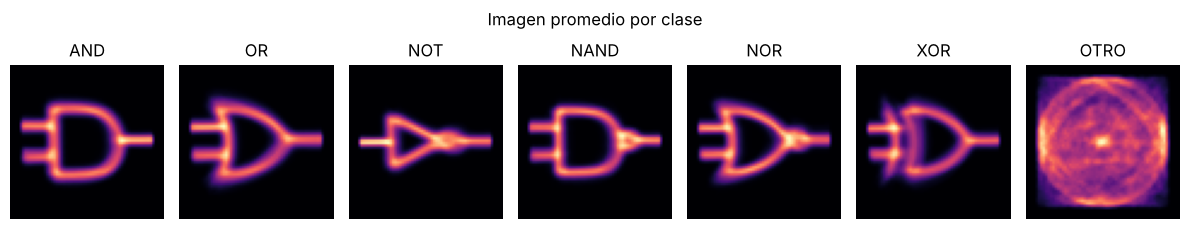

In [6]:
fig, axes = plt.subplots(1, len(CLASES), figsize=(12, 2.4))
for i, clase in enumerate(CLASES):
    axes[i].imshow(X[y == i].mean(axis=0), cmap="magma"); axes[i].set_title(clase); axes[i].axis("off")
plt.suptitle("Imagen promedio por clase"); plt.tight_layout(); plt.show()

## 4. División en entrenamiento, validación y prueba

- **Entrenamiento (70%)**: la red aprende con estos datos.
- **Validación (15%)**: sirve para decidir cuándo dejar de entrenar.
- **Prueba (15%)**: solo se usa al final para medir el rendimiento real.

La división es **estratificada** (cada conjunto tiene la misma proporción de cada compuerta) y se guardan los índices para reutilizar exactamente la misma división en todos los experimentos.

In [7]:
from sklearn.model_selection import train_test_split
import logging
import keras
from keras import layers

logging.getLogger("tensorflow").setLevel(logging.ERROR)  # oculta avisos internos de TensorFlow

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

indices = np.arange(len(y))
idx_train, idx_tmp = train_test_split(indices, test_size=0.30, stratify=y, random_state=SEMILLA)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEMILLA)

def separar(Xs):
    Xs = Xs[..., None]  # canal de color
    return Xs[idx_train], Xs[idx_val], Xs[idx_test]

X_train, X_val, X_test = separar(X)
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
print("Entrenamiento:", X_train.shape, " Validación:", X_val.shape, " Prueba:", X_test.shape)

Entrenamiento: (2450, 64, 64, 1)  Validación: (525, 64, 64, 1)  Prueba: (525, 64, 64, 1)


## 5. Modelo base: perceptrón multicapa (MLP)

Primero una red densa simple, que ve la imagen como un vector de píxeles sin estructura espacial. Sirve como punto de comparación para la CNN.

In [8]:
EPOCAS = 60

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)]

def crear_mlp(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(CLASES), activation="softmax"),
    ], name="MLP")

mlp = crear_mlp(TAM)
mlp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mlp.summary()
hist_mlp = mlp.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                   batch_size=64, callbacks=callbacks(), verbose=2)

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,082,631 (4.13 MB)

 Trainable params: 1,082,631 (4.13 MB)

 Non-trainable params: 0 (0.00 B)

...

39/39 - 0s - 9ms/step - accuracy: 0.9992 - loss: 0.0034 - val_accuracy: 0.9905 - val_loss: 0.0468 - learning_rate: 2.5000e-04


Epoch 28/60


39/39 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9905 - val_loss: 0.0480 - learning_rate: 2.5000e-04


Epoch 29/60


39/39 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.9943 - val_loss: 0.0435 - learning_rate: 2.5000e-04


## 6. Red neuronal convolucional (CNN)

La CNN aprende filtros que detectan bordes, curvas y círculos, y luego los combina. Eso la hace adecuada para distinguir detalles como el círculo de NAND o la curva extra de XOR.

**Aumento de datos:** durante el entrenamiento cada imagen se rota (±10°), se desplaza y se acerca o aleja un poco al azar, para simular la variación natural entre personas. **No** se aplica volteo horizontal: una compuerta volteada tendría la salida a la izquierda, que no es un dibujo válido.

**Arquitectura:** tres bloques de convolución + max pooling (32, 64 y 128 filtros), seguidos de una capa densa con dropout para reducir el sobreajuste.

In [9]:
def crear_aumento():
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode="constant"),
        layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
        layers.RandomZoom(0.1, fill_mode="constant"),
    ], name="aumento_de_datos")

def crear_cnn(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        crear_aumento(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(CLASES), activation="softmax"),
    ], name="CNN")

cnn = crear_cnn(TAM)
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
hist_cnn = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                   batch_size=64, callbacks=callbacks(), verbose=2)

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,188,455 (4.53 MB)

 Trainable params: 1,188,455 (4.53 MB)

 Non-trainable params: 0 (0.00 B)

...

39/39 - 10s - 267ms/step - accuracy: 0.9935 - loss: 0.0222 - val_accuracy: 0.9943 - val_loss: 0.0184 - learning_rate: 5.0000e-04


Epoch 19/60


39/39 - 6s - 160ms/step - accuracy: 0.9967 - loss: 0.0115 - val_accuracy: 0.9943 - val_loss: 0.0228 - learning_rate: 5.0000e-04


Epoch 20/60


39/39 - 6s - 159ms/step - accuracy: 0.9963 - loss: 0.0134 - val_accuracy: 0.9962 - val_loss: 0.0136 - learning_rate: 5.0000e-04


### Curvas de entrenamiento

Si la pérdida de validación sube mientras la de entrenamiento baja, la red está memorizando (sobreajuste). `EarlyStopping` detiene el entrenamiento en ese punto y recupera los mejores pesos.

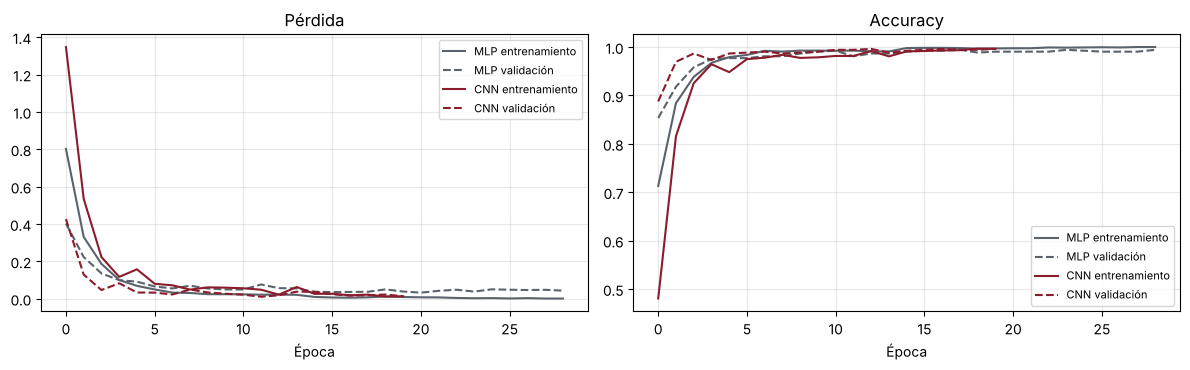

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for h, nombre, color in [(hist_mlp, "MLP", "#5a626c"), (hist_cnn, "CNN", "#8a1c2b")]:
    axes[0].plot(h.history["loss"], color=color, label=f"{nombre} entrenamiento")
    axes[0].plot(h.history["val_loss"], color=color, ls="--", label=f"{nombre} validación")
    axes[1].plot(h.history["accuracy"], color=color, label=f"{nombre} entrenamiento")
    axes[1].plot(h.history["val_accuracy"], color=color, ls="--", label=f"{nombre} validación")
axes[0].set_title("Pérdida"); axes[1].set_title("Accuracy")
for a in axes:
    a.set_xlabel("Época"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Métricas en el conjunto de prueba

- **Accuracy:** porcentaje de dibujos clasificados correctamente.
- **Precisión** de una clase: de los dibujos que la red dijo que eran NAND, cuántos lo eran de verdad.
- **Recall** de una clase: de los NAND reales, cuántos encontró la red.
- **F1:** media armónica de precisión y recall.
- **Matriz de confusión:** fila = compuerta real, columna = compuerta predicha. Lo que está fuera de la diagonal son errores.

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

def evaluar(modelo, Xt, yt):
    prob = modelo.predict(Xt, verbose=0)
    pred = prob.argmax(axis=1)
    return pred, prob

pred_mlp, _ = evaluar(mlp, X_test, y_test)
pred_cnn, prob_cnn = evaluar(cnn, X_test, y_test)

for nombre, pred in [("MLP", pred_mlp), ("CNN", pred_cnn)]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, pred, target_names=CLASES, digits=3))

===== MLP =====
              precision    recall  f1-score   support

         AND      0.986     0.960     0.973        75
          OR      0.948     0.973     0.961        75
         NOT      1.000     1.000     1.000        75
        NAND      0.961     0.973     0.967        75
         NOR      0.974     1.000     0.987        75
         XOR      1.000     0.973     0.986        75
        OTRO      0.986     0.973     0.980        75

    accuracy                          0.979       525
   macro avg      0.979     0.979     0.979       525
weighted avg      0.979     0.979     0.979       525

===== CNN =====
              precision    recall  f1-score   support

         AND      1.000     0.987     0.993        75
          OR      0.987     1.000     0.993        75
         NOT      1.000     1.000     1.000        75
        NAND      1.000     0.987     0.993        75
         NOR      0.987     1.000     0.993        75
         XOR      1.000     1.000     1.000   

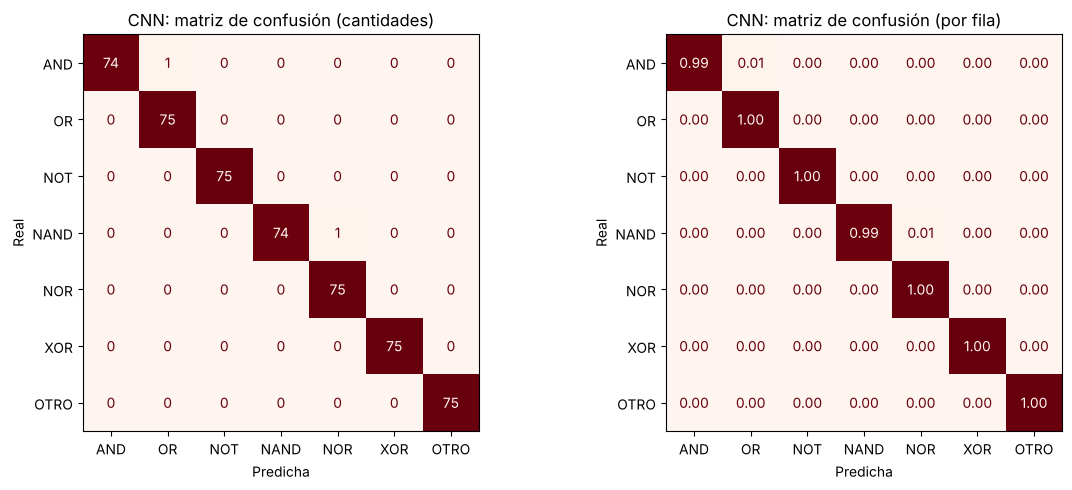

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, pred_cnn)
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title("CNN: matriz de confusión (cantidades)")
cm_norm = confusion_matrix(y_test, pred_cnn, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASES).plot(ax=axes[1], cmap="Reds", colorbar=False, values_format=".2f")
axes[1].set_title("CNN: matriz de confusión (por fila)")
for a in axes:
    a.set_xlabel("Predicha"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

### ¿Reconoce lo que no es una compuerta?

Los 75 dibujos de OTRO del conjunto de prueba salen del mismo generador que los de entrenamiento, así que medirlos es fácil para la red. Una prueba más honesta son dibujos que el generador **no** produce: formas y símbolos dibujados aparte, y compuertas reales giradas 90° (que siguen siendo compuertas, pero la red nunca las vio así).

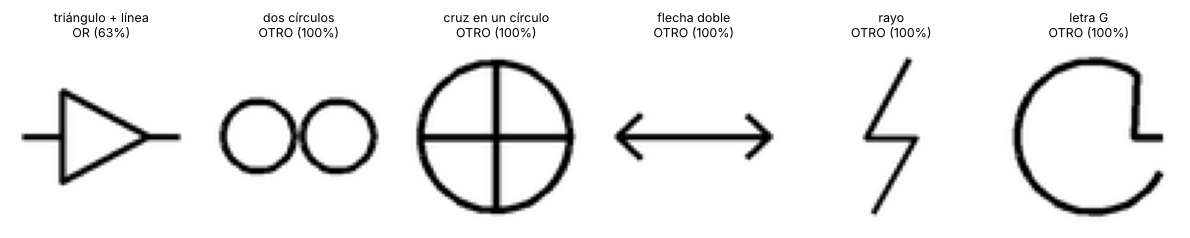

Formas nuevas reconocidas como OTRO: 5 de 6
Compuertas giradas 90°: 100% dichas OTRO, 0% reconocidas, 0% confundidas con otra compuerta


In [13]:
from PIL import ImageDraw

def lienzo(trazos, grosor=8):
    """Dibuja trazos (listas de puntos en 0..256) como en el lienzo de la app y aplica el preprocesamiento."""
    img = Image.new("RGBA", (256, 256), (0, 0, 0, 0)); d = ImageDraw.Draw(img)
    for t in trazos:
        d.line(t, fill="black", width=grosor, joint="curve")
    caja = img.getchannel("A").getbbox()
    x0, y0, x1, y1 = caja
    lado = int(max(x1 - x0, y1 - y0) * (1 + 2 * MARGEN))
    cuadrado = Image.new("L", (lado, lado), 0)
    cuadrado.paste(img.getchannel("A").crop(caja), ((lado - (x1 - x0)) // 2, (lado - (y1 - y0)) // 2))
    return np.asarray(cuadrado.resize((TAM, TAM), Image.Resampling.LANCZOS), dtype=np.float32) / 255.0

def circulo(cx, cy, r, n=40):
    return [(cx + r * np.cos(t), cy + r * np.sin(t)) for t in np.linspace(0, 2 * np.pi, n)]

extras = {
    "triángulo + línea": [[(40, 128), (90, 128)], [(90, 70), (90, 186), (200, 128), (90, 70)], [(200, 128), (240, 128)]],
    "dos círculos": [circulo(90, 128, 40), circulo(180, 128, 40)],
    "cruz en un círculo": [circulo(128, 128, 80), [(128, 48), (128, 208)], [(48, 128), (208, 128)]],
    "flecha doble": [[(30, 128), (226, 128)], [(60, 100), (30, 128), (60, 156)], [(196, 100), (226, 128), (196, 156)]],
    "rayo": [[(150, 20), (90, 130), (160, 130), (100, 236)]],
    "letra G": [circulo(128, 128, 80)[3:34] + [(170, 128), (200, 128)]],
}
X_extra = np.stack([lienzo(t) for t in extras.values()])[..., None]
# 60 compuertas de prueba giradas 90°: siguen siendo compuertas
otro = CLASES.index("OTRO")
idx_comp = np.where(y_test != otro)[0][:60]
giradas = np.rot90(X_test[idx_comp], k=1, axes=(1, 2))
p_extra = cnn.predict(X_extra, verbose=0)
p_giradas = cnn.predict(giradas, verbose=0).argmax(axis=1)

fig, axes = plt.subplots(1, len(extras), figsize=(2 * len(extras), 2.4))
for a, nombre, img, p in zip(axes, extras, X_extra, p_extra):
    a.imshow(img[..., 0], cmap="gray_r"); a.axis("off")
    a.set_title(f"{nombre}\n{CLASES[p.argmax()]} ({p.max():.0%})", fontsize=9)
plt.tight_layout(); plt.show()
print(f"Formas nuevas reconocidas como OTRO: {(p_extra.argmax(axis=1) == otro).sum()} de {len(extras)}")
print(f"Compuertas giradas 90°: {(p_giradas == otro).mean():.0%} dichas OTRO, "
      f"{(p_giradas == y_test[idx_comp]).mean():.0%} reconocidas, {((p_giradas != otro) & (p_giradas != y_test[idx_comp])).mean():.0%} confundidas con otra compuerta")

## 8. Parejas difíciles y análisis de errores

Estas parejas solo se diferencian por un detalle pequeño. Se mide qué porcentaje de los dibujos de una compuerta se confundió con la otra (en ambos sentidos).

In [14]:
PAREJAS = [("AND", "NAND"), ("OR", "NOR"), ("OR", "XOR"), ("NOR", "XOR")]

def confusion_parejas(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(len(CLASES)))
    filas = []
    for a, b in PAREJAS:
        ia, ib = CLASES.index(a), CLASES.index(b)
        filas.append((f"{a} → {b}", 100 * cm[ia, ib] / max(1, cm[ia].sum())))
        filas.append((f"{b} → {a}", 100 * cm[ib, ia] / max(1, cm[ib].sum())))
    return filas

print(f"{'Confusión':<14}{'MLP':>8}{'CNN':>8}")
for (texto, p_mlp), (_, p_cnn) in zip(confusion_parejas(y_test, pred_mlp), confusion_parejas(y_test, pred_cnn)):
    print(f"{texto:<14}{p_mlp:>7.1f}%{p_cnn:>7.1f}%")

Confusión          MLP     CNN
AND → NAND        1.3%    0.0%
NAND → AND        0.0%    0.0%
OR → NOR          1.3%    0.0%
NOR → OR          0.0%    0.0%
OR → XOR          0.0%    0.0%
XOR → OR          2.7%    0.0%
NOR → XOR         0.0%    0.0%
XOR → NOR         0.0%    0.0%


### Dibujos que la CNN clasificó mal

2 errores de 525 dibujos de prueba


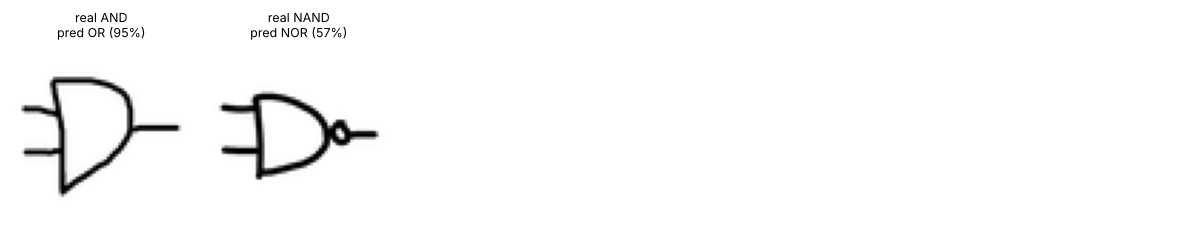

In [15]:
errores = np.where(pred_cnn != y_test)[0]
print(f"{len(errores)} errores de {len(y_test)} dibujos de prueba")
n = min(18, len(errores))
if n:
    cols = 6; filas = int(np.ceil(n / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(12, 2.3 * filas), squeeze=False)
    for k, a in enumerate(axes.flat):
        a.axis("off")
        if k < n:
            i = errores[k]
            a.imshow(X_test[i, ..., 0], cmap="gray_r")
            a.set_title(f"real {CLASES[y_test[i]]}\npred {CLASES[pred_cnn[i]]} ({prob_cnn[i].max():.0%})", fontsize=9)
    plt.tight_layout(); plt.show()

### Comparación MLP contra CNN

In [16]:
resumen = []
for nombre, modelo, pred in [("MLP", mlp, pred_mlp), ("CNN", cnn, pred_cnn)]:
    resumen.append((nombre, accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"), modelo.count_params()))
print(f"{'Modelo':<8}{'Accuracy':>10}{'F1 macro':>10}{'Parámetros':>13}")
for nombre, acc, f1, params in resumen:
    print(f"{nombre:<8}{acc:>10.3f}{f1:>10.3f}{params:>13,}")

Modelo    Accuracy  F1 macro   Parámetros
MLP          0.979     0.979    1,082,631
CNN          0.996     0.996    1,188,455


## 9. Experimento: ¿cuánto importa la resolución?

MNIST usa imágenes de 28×28. ¿Alcanza esa resolución para ver el círculo de NAND y NOR? Se entrena la **misma CNN** con la **misma división de datos** a 16×16, 28×28 y 64×64, y se compara el resultado.

Hipótesis: a baja resolución el círculo se reduce a uno o dos píxeles, así que deberían aumentar las confusiones AND↔NAND y OR↔NOR.

In [17]:
RESOLUCIONES = [16, 28, 64]
resultados_res = {}
for tam in RESOLUCIONES:
    keras.utils.set_random_seed(SEMILLA)
    Xr_train, Xr_val, Xr_test = separar(a_matriz(recortes, tam))
    modelo = crear_cnn(tam)
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    modelo.fit(Xr_train, y_train, validation_data=(Xr_val, y_val), epochs=EPOCAS,
               batch_size=64, callbacks=callbacks(), verbose=0)
    pred = modelo.predict(Xr_test, verbose=0).argmax(axis=1)
    parejas = dict(confusion_parejas(y_test, pred))
    resultados_res[tam] = {
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred, average="macro"),
        "and_nand": (parejas["AND → NAND"] + parejas["NAND → AND"]) / 2,
        "or_nor": (parejas["OR → NOR"] + parejas["NOR → OR"]) / 2,
        "ejemplo": Xr_test[np.where(y_test == CLASES.index("NAND"))[0][0], ..., 0],
    }
    print(f"{tam}×{tam}: accuracy {resultados_res[tam]['accuracy']:.3f}")

16×16: accuracy 0.981


28×28: accuracy 0.996


64×64: accuracy 0.989


Resolución    Accuracy  F1 macro   AND↔NAND   OR↔NOR
16×16            0.981     0.981       0.0%     0.0%
28×28            0.996     0.996       0.7%     0.0%
64×64            0.989     0.989       0.0%     0.0%


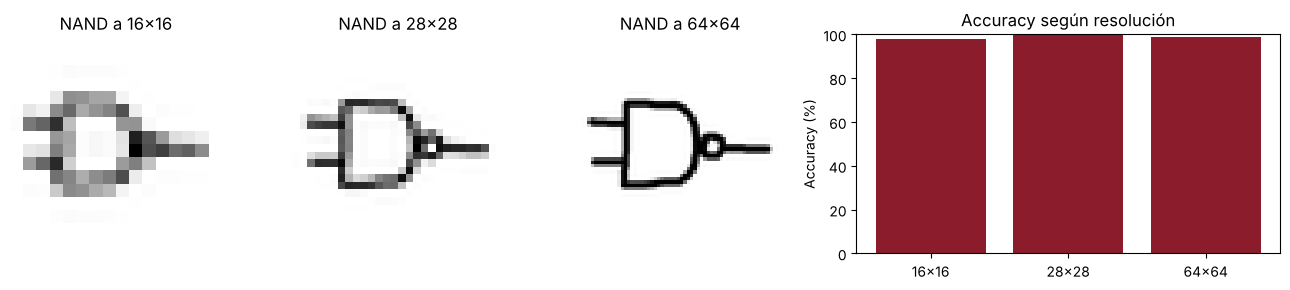

In [18]:
print(f"{'Resolución':<12}{'Accuracy':>10}{'F1 macro':>10}{'AND↔NAND':>11}{'OR↔NOR':>9}")
for tam, r in resultados_res.items():
    print(f"{f'{tam}×{tam}':<12}{r['accuracy']:>10.3f}{r['f1']:>10.3f}{r['and_nand']:>10.1f}%{r['or_nor']:>8.1f}%")

fig, axes = plt.subplots(1, len(RESOLUCIONES) + 1, figsize=(13, 3), gridspec_kw={"width_ratios": [1] * len(RESOLUCIONES) + [2]})
for a, tam in zip(axes, RESOLUCIONES):
    a.imshow(resultados_res[tam]["ejemplo"], cmap="gray_r"); a.set_title(f"NAND a {tam}×{tam}"); a.axis("off")
axes[-1].bar([f"{t}×{t}" for t in RESOLUCIONES], [100 * resultados_res[t]["accuracy"] for t in RESOLUCIONES], color="#8a1c2b")
axes[-1].set_ylabel("Accuracy (%)"); axes[-1].set_ylim(0, 100); axes[-1].set_title("Accuracy según resolución")
plt.tight_layout(); plt.show()

## 10. Generalización a personas nuevas

En la división anterior, los dibujos de una misma persona aparecen tanto en entrenamiento como en prueba, así que la red puede aprender el estilo de cada uno. Una prueba más exigente es **dejar fuera a una persona completa**: entrenar con las demás y evaluar solo con sus dibujos. Se repite para cada persona (validación cruzada por grupos).

Se necesitan al menos 3 personas con nombre. Los dibujos marcados como `anonimo` y los de OTRO (`sintetico`) se usan solo para entrenar.

In [19]:
personas = [a for a, n in collections.Counter(autores).most_common() if a not in ("anonimo", "sintetico") and n >= 30]
if len(personas) < 3:
    print("Se necesitan al menos 3 personas con 30 dibujos o más. Personas encontradas:", personas)
else:
    resultados_personas = {}
    errores_personas = collections.Counter()
    for persona in personas:
        keras.utils.set_random_seed(SEMILLA)
        prueba = autores == persona
        idx_resto = np.where(~prueba)[0]
        idx_tr, idx_va = train_test_split(idx_resto, test_size=0.15, stratify=y[idx_resto], random_state=SEMILLA)
        modelo = crear_cnn(TAM)
        modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        modelo.fit(X[idx_tr, ..., None], y[idx_tr], validation_data=(X[idx_va, ..., None], y[idx_va]),
                   epochs=EPOCAS, batch_size=64, callbacks=callbacks(), verbose=0)
        pred = modelo.predict(X[prueba, ..., None], verbose=0).argmax(axis=1)
        resultados_personas[persona] = (accuracy_score(y[prueba], pred), int(prueba.sum()))
        errores = collections.Counter((CLASES[r], CLASES[p]) for r, p in zip(y[prueba], pred) if r != p)
        errores_personas.update(errores)
        detalle = ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores.most_common(3)) or "sin errores"
        print(f"Sin {persona:<12} accuracy en sus {prueba.sum()} dibujos: {resultados_personas[persona][0]:.3f}  ({detalle})")
    media = np.mean([acc for acc, _ in resultados_personas.values()])
    print(f"\nAccuracy promedio con personas no vistas: {media:.3f}")
    print("Confusiones más comunes con personas no vistas:",
          ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores_personas.most_common(5)) or "ninguna")

Sin faalvial     accuracy en sus 1133 dibujos: 0.973  (OR→AND ×22, NOR→NAND ×9)


Sin christmas    accuracy en sus 873 dibujos: 1.000  (sin errores)


Sin dodo         accuracy en sus 685 dibujos: 0.987  (XOR→OR ×8, AND→OR ×1)


Sin omar         accuracy en sus 297 dibujos: 1.000  (sin errores)

Accuracy promedio con personas no vistas: 0.990
Confusiones más comunes con personas no vistas: OR→AND ×22, NOR→NAND ×9, XOR→OR ×8, AND→OR ×1


## 11. Global Average Pooling y Class Activation Maps (CAM)

En la CNN de la sección 6, el 88% de los parámetros está en una sola capa: la densa de 128 neuronas que recibe los 8×8×128 = 8192 valores aplanados. **Global Average Pooling (GAP)**, visto en la clase de ResNet, reemplaza ese aplanado: promedia cada uno de los 128 mapas de la última convolución y deja un solo número por mapa. Esos 128 promedios van directo a la capa de salida.

Además de reducir parámetros, GAP permite ver **dónde mira la red**. Como cada clase es una suma ponderada de los 128 promedios, se puede hacer la misma suma ponderada con los mapas completos (antes de promediar). El resultado es el **Class Activation Map** de esa clase: un mapa de calor que marca las zonas del dibujo que más empujaron hacia esa respuesta ([Zhou et al., 2016](https://arxiv.org/abs/1512.04150)).

Se entrena una CNN igual a la de la sección 6 con dos cambios: se quita el último max pooling (para que el mapa de calor sea de 16×16 y no de 8×8) y se cambia `Flatten` + `Dense(128)` por `GlobalAveragePooling2D`. Misma división de datos, mismo aumento de datos y mismas épocas.

In [20]:
def crear_cnn_gap(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        crear_aumento(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="ultima_conv"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(len(CLASES), activation="softmax", name="salida"),
    ], name="CNN_GAP")

keras.utils.set_random_seed(SEMILLA)
cnn_gap = crear_cnn_gap(TAM)
cnn_gap.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_gap.summary()
hist_gap = cnn_gap.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                       batch_size=64, callbacks=callbacks(), verbose=2)

Model: "CNN_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ultima_conv (Conv2D)            │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,751 (545.90 KB)

 Trainable params: 139,751 (545.90 KB)

 Non-trainable params: 0 (0.00 B)

...

39/39 - 5s - 129ms/step - accuracy: 0.9886 - loss: 0.0391 - val_accuracy: 0.9848 - val_loss: 0.0512 - learning_rate: 5.0000e-04


Epoch 30/60


39/39 - 6s - 154ms/step - accuracy: 0.9914 - loss: 0.0306 - val_accuracy: 0.9771 - val_loss: 0.0661 - learning_rate: 5.0000e-04


Epoch 31/60


39/39 - 6s - 153ms/step - accuracy: 0.9906 - loss: 0.0245 - val_accuracy: 0.9771 - val_loss: 0.0692 - learning_rate: 5.0000e-04


In [21]:
pred_gap, prob_gap = evaluar(cnn_gap, X_test, y_test)
print(classification_report(y_test, pred_gap, target_names=CLASES, digits=3))

print(f"{'Modelo':<10}{'Accuracy':>10}{'F1 macro':>10}{'Errores':>9}{'Parámetros':>13}")
for nombre, modelo, pred in [("CNN", cnn, pred_cnn), ("CNN + GAP", cnn_gap, pred_gap)]:
    print(f"{nombre:<10}{accuracy_score(y_test, pred):>10.3f}{f1_score(y_test, pred, average='macro'):>10.3f}"
          f"{int((pred != y_test).sum()):>9}{modelo.count_params():>13,}")

              precision    recall  f1-score   support

         AND      0.974     0.987     0.980        75
          OR      1.000     0.973     0.986        75
         NOT      1.000     1.000     1.000        75
        NAND      0.987     1.000     0.993        75
         NOR      1.000     1.000     1.000        75
         XOR      1.000     0.987     0.993        75
        OTRO      0.987     1.000     0.993        75

    accuracy                          0.992       525
   macro avg      0.992     0.992     0.992       525
weighted avg      0.992     0.992     0.992       525

Modelo      Accuracy  F1 macro  Errores   Parámetros
CNN            0.996     0.996        2    1,188,455
CNN + GAP      0.992     0.992        4      139,751


### Cómo se calcula el CAM

Para un dibujo y una clase *c*:

1. Se obtienen los 128 mapas de la última convolución (16×16 cada uno).
2. Cada mapa se multiplica por el peso que la capa de salida le da a la clase *c* y se suman: `CAM = Σ_k w[k, c] · mapa_k`.
3. Se dejan solo los valores positivos, se escala de 0 a 1 y se agranda a 64×64 para ponerlo encima del dibujo.

Zonas claras = partes del dibujo que más aportaron a la clase predicha.

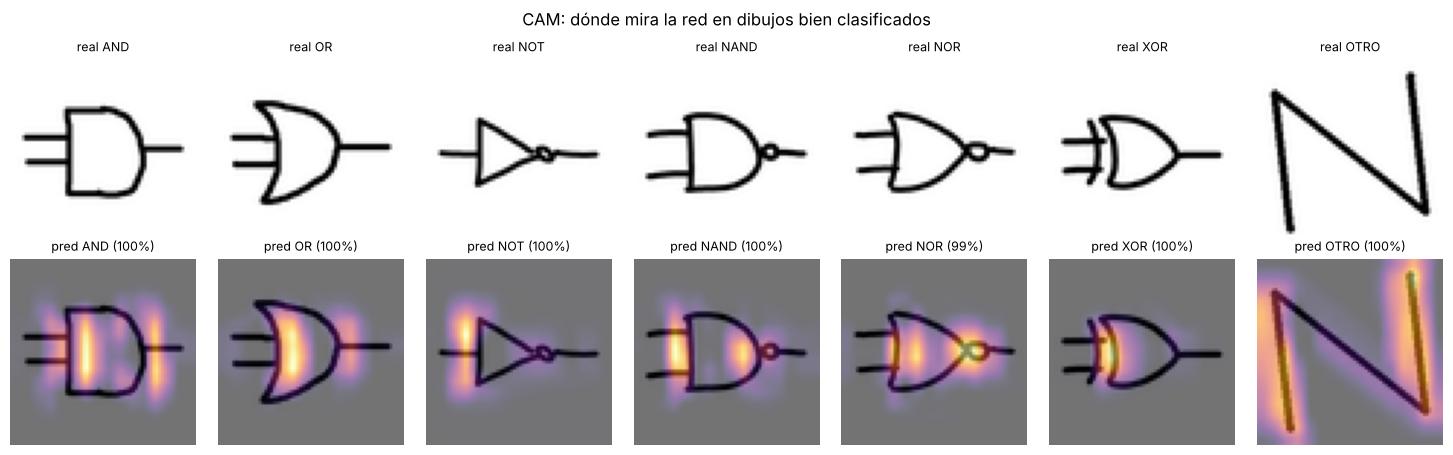

In [22]:
from PIL import Image as ImagenPIL

# Modelo que devuelve los mapas de la última convolución y las probabilidades.
# Se arma pasando una entrada por las capas entrenadas, sin el aumento de datos.
entrada = keras.Input((TAM, TAM, 1))
x = entrada
for capa in cnn_gap.layers[1:]:
    x = capa(x)
    if capa.name == "ultima_conv":
        mapas_conv = x
extractor = keras.Model(entrada, [mapas_conv, x])
pesos_salida = cnn_gap.get_layer("salida").get_weights()[0]   # (128 mapas, una columna por clase)

def mapa_cam(imagen, clase=None):
    mapas, prob = extractor.predict(imagen[None], verbose=0)
    clase = int(prob[0].argmax()) if clase is None else clase
    cam = np.maximum(mapas[0] @ pesos_salida[:, clase], 0)
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(ImagenPIL.fromarray(cam.astype(np.float32)).resize((TAM, TAM), ImagenPIL.Resampling.BILINEAR))
    return cam, clase, prob[0]

def mostrar_cams(indices, titulo):
    cols = len(indices)
    fig, axes = plt.subplots(2, cols, figsize=(2.1 * cols, 4.6), squeeze=False)
    for k, i in enumerate(indices):
        cam, clase, prob = mapa_cam(X_test[i])
        axes[0, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[0, k].set_title(f"real {CLASES[y_test[i]]}", fontsize=9)
        axes[1, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[1, k].imshow(cam, cmap="inferno", alpha=0.55)
        axes[1, k].set_title(f"pred {CLASES[clase]} ({prob[clase]:.0%})", fontsize=9)
        for a in axes[:, k]:
            a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

# Un dibujo bien clasificado de cada compuerta
rng = np.random.default_rng(1)
ejemplos = [rng.choice(np.where((y_test == c) & (pred_gap == y_test))[0]) for c in range(len(CLASES))]
mostrar_cams(ejemplos, "CAM: dónde mira la red en dibujos bien clasificados")

Los dibujos que falló alguno de los dos modelos (la CNN de la sección 6 o la CNN con GAP). El CAM muestra en qué se fijó la red con GAP al decidir.

5 dibujos fallados por alguno de los dos modelos
  dibujo 20: real XOR, CNN dijo XOR, CNN + GAP dijo OTRO
  dibujo 123: real OR, CNN dijo OR, CNN + GAP dijo AND
  dibujo 127: real OR, CNN dijo OR, CNN + GAP dijo AND
  dibujo 262: real AND, CNN dijo OR, CNN + GAP dijo NAND
  dibujo 423: real NAND, CNN dijo NOR, CNN + GAP dijo NAND


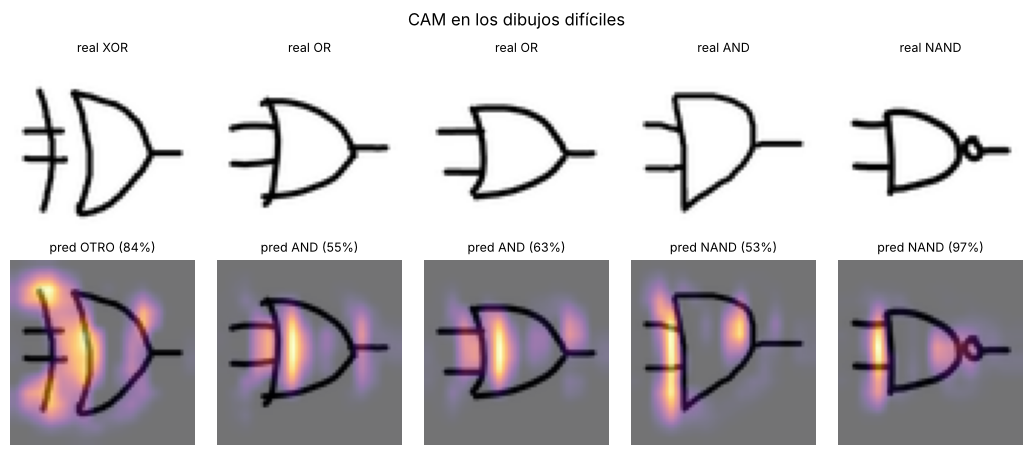

In [23]:
fallados = np.where((pred_cnn != y_test) | (pred_gap != y_test))[0]
print(f"{len(fallados)} dibujos fallados por alguno de los dos modelos")
for i in fallados:
    print(f"  dibujo {i}: real {CLASES[y_test[i]]}, CNN dijo {CLASES[pred_cnn[i]]}, CNN + GAP dijo {CLASES[pred_gap[i]]}")
if len(fallados):
    mostrar_cams(list(fallados[:10]), "CAM en los dibujos difíciles")

**Lectura de los mapas:**

- En los dibujos bien clasificados, la red mira lo que distingue a cada clase: la parte trasera recta del AND, la trasera curva del OR, la trasera del NOT y del NAND, la burbuja del NOR y la curva extra del XOR. En OTRO (aquí una letra N) mira los propios trazos, que no se parecen a ninguna compuerta.
- La CNN con GAP falló 4 dibujos. Dos OR con la trasera casi recta salieron AND: el mapa está justo en esa trasera. Un XOR con la curva extra larga y separada salió OTRO: la red se fijó en esa curva suelta. Y un AND con la base inclinada salió NAND con poca seguridad (53%).
- **Por qué GAP pierde algo de precisión (inferido de los mapas):** al promediar cada mapa sobre toda la imagen, la red sabe *qué* formas aparecen pero no *dónde* están unas respecto de otras. La CNN de la sección 6 conserva esa posición en `Flatten` + `Dense`, a cambio de 8.5 veces más parámetros. Aquí la diferencia es de solo 2 dibujos, así que también puede deberse a la variación entre entrenamientos.

## Guardar el modelo

In [24]:
cnn.save("modelo_compuertas.keras")
with open("clases.json", "w") as f:
    json.dump(CLASES, f)
print("Guardado modelo_compuertas.keras y clases.json")

Guardado modelo_compuertas.keras y clases.json


### Exportar los pesos para la app ("Adivina tu dibujo")

La app no usa TensorFlow, porque ocupa más de 1 GB y el plan gratuito de PythonAnywhere da 512 MB. Pero una red ya entrenada solo hace multiplicaciones con sus pesos, así que la app repite las mismas capas con numpy (archivo `prediccion.py`). Para eso basta guardar los pesos de las capas de convolución y densas en `pesos_cnn.npz`. El aumento de datos y el dropout no tienen pesos: solo actúan durante el entrenamiento.

Después se copia `pesos_cnn.npz` al repositorio, junto a `main.py`, y en PythonAnywhere se hace `git pull` y **Reload**. Si se cambia la arquitectura de la CNN, hay que cambiar también la función `predecir` de `prediccion.py`.

In [25]:
pesos = [w for capa in cnn.layers if isinstance(capa, (layers.Conv2D, layers.Dense)) for w in capa.get_weights()]
np.savez("pesos_cnn.npz", *pesos)
print(f"Guardado pesos_cnn.npz: {len(pesos)} arreglos, {sum(w.size for w in pesos):,} pesos")

try:
    from google.colab import files
    files.download("pesos_cnn.npz")
except ImportError:
    pass

Guardado pesos_cnn.npz: 14 arreglos, 1,188,455 pesos


## Resumen de resultados

Esta celda imprime los números clave para copiarlos en las conclusiones y en la exposición.

In [26]:
acc_mlp, f1_mlp = resumen[0][1], resumen[0][2]
acc_cnn, f1_cnn = resumen[1][1], resumen[1][2]
print(f"Dataset: {len(y)} dibujos; personas: {len(set(autores) - {'sintetico', 'anonimo'})}")
print(f"MLP: accuracy {acc_mlp:.1%}, F1 macro {f1_mlp:.3f}")
print(f"CNN: accuracy {acc_cnn:.1%}, F1 macro {f1_cnn:.3f}")
f1_clases = f1_score(y_test, pred_cnn, average=None)
peores = [CLASES[i] for i in np.where(np.isclose(f1_clases, f1_clases.min()))[0]]
if len(peores) == len(CLASES):
    print(f"Clase más difícil para la CNN: ninguna, todas con F1 {f1_clases.min():.3f} en prueba")
else:
    print(f"Clases con menor F1 en la CNN: {', '.join(peores)} (F1 {f1_clases.min():.3f})")
for tam, r in resultados_res.items():
    print(f"CNN a {tam}×{tam}: accuracy {r['accuracy']:.1%}, confusión AND↔NAND {r['and_nand']:.1f}%, OR↔NOR {r['or_nor']:.1f}%")
if "resultados_personas" in globals():
    print(f"CNN con personas no vistas: accuracy promedio {media:.1%}")
    print("Confusiones más comunes con personas no vistas:",
          ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores_personas.most_common(3)) or "ninguna")

Dataset: 3500 dibujos; personas: 4
MLP: accuracy 97.9%, F1 macro 0.979
CNN: accuracy 99.6%, F1 macro 0.996
Clases con menor F1 en la CNN: AND, NAND (F1 0.993)
CNN a 16×16: accuracy 98.1%, confusión AND↔NAND 0.0%, OR↔NOR 0.0%
CNN a 28×28: accuracy 99.6%, confusión AND↔NAND 0.7%, OR↔NOR 0.0%
CNN a 64×64: accuracy 98.9%, confusión AND↔NAND 0.0%, OR↔NOR 0.0%
CNN con personas no vistas: accuracy promedio 99.0%
Confusiones más comunes con personas no vistas: OR→AND ×22, NOR→NAND ×9, XOR→OR ×8


## 12. Conclusiones

1. **CNN contra MLP:** la CNN obtuvo 99.6% de accuracy (2 errores en 525 dibujos de prueba) frente a 97.9% del MLP (11 errores). Las convoluciones reconocen formas locales (rectas, curvas, círculos) aunque no estén exactamente en el mismo lugar, mientras que el MLP ve píxeles sueltos.
2. **Parejas difíciles:** la CNN no confundió ninguna de las parejas que solo se diferencian por la burbuja (AND/NAND y OR/NOR). Sus dos errores fueron un AND leído como OR y un NAND leído como NOR, en dibujos con la base inclinada, que es justamente lo que separa la familia AND de la familia OR. El MLP sí confundió XOR → OR (2.7%), AND → NAND (1.3%) y OR → NOR (1.3%).
3. **La clase OTRO:** sin ella, la red tenía que elegir una compuerta para cualquier dibujo, y lo hacía con mucha seguridad (un círculo salía AND con 100%). Con 500 dibujos generados de letras, números, formas, flechas y garabatos, reconoció los 75 OTRO de prueba y 5 de 6 formas dibujadas aparte (dos círculos, cruz en un círculo, flecha doble, rayo y una G). La que falló fue un triángulo con una línea a cada lado, que es una compuerta *buffer* (no está entre nuestras clases) y salió OR con 63%. Además, las 60 compuertas giradas 90° salieron todas OTRO: la red ya no inventa una compuerta para algo que no reconoce, pero tampoco reconoce compuertas inclinadas, porque el aumento de datos solo las gira ±10°.
4. **Resolución:** 98.1% a 16×16, 99.6% a 28×28 y 98.9% a 64×64. Las diferencias son menores a 1 punto, y la misma CNN a 64×64 dio 99.6% en la sección 7 y 98.9% aquí, así que diferencias de ese tamaño son variación entre entrenamientos. Desde 28×28 la resolución alcanza: la burbuja de NAND y NOR sobrevive incluso a 16×16 y ninguna resolución confundió OR↔NOR.
5. **Personas nuevas:** entrenando sin una persona y probando con sus dibujos, la accuracy promedio fue 99.0%. Christmas y omar obtuvieron 100%. Sin dodo bajó a 98.7% (XOR → OR ×8) y sin faalvial a 97.3%, sobre todo por OR → AND (22) y NOR → NAND (9); por lo que se ve en sus dibujos, faalvial hace la parte trasera del OR casi recta y el frente redondeado, un estilo que los demás no usan. El estilo personal influye, y más personas aportando datos mejorarían la generalización.
6. **GAP y CAM:** cambiar `Flatten` + `Dense(128)` por Global Average Pooling redujo los parámetros de 1 188 455 a 139 751 (8.5 veces menos) con 99.2% de accuracy (4 errores) frente a 99.6%. Los mapas CAM muestran que la red mira lo que distingue a cada compuerta: la trasera recta del AND, la curva del OR, la burbuja y la curva extra del XOR. En los errores se queda con una sola pista, por ejemplo una trasera casi recta en un OR.
7. **Calidad de los datos:** antes de entrenar se revisaron los 3000 dibujos de compuertas con modelos de validación cruzada. 9 (0.3%) estaban mal hechos (incompletos, con la forma de otra compuerta o con un punto suelto que desplaza el recorte) y se reemplazaron por dibujos nuevos.
8. **Limitaciones y trabajo futuro:** las compuertas vienen de solo 4 personas, y los dibujos de OTRO son generados: los de prueba salen del mismo generador, así que su 100% es optimista, y garabatos reales de personas pueden ser distintos. Las compuertas inclinadas más de unos 20° se leen como OTRO; ampliar la rotación del aumento de datos lo corregiría. Por último, el sistema clasifica compuertas sueltas: para digitalizar un circuito completo haría falta detectar y separar cada compuerta y sus conexiones (detección de objetos).